In [1]:
import os
import json
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import cv2

C:\Users\saqib\anaconda3\envs\thermal_fault\lib\site-packages\google\api_core\_python_version_support.py:254: FutureWarning: You are using a Python version (3.10.21) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2026-10-04). Please upgrade to the latest Python version, or at least Python 3.11, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)
C:\Users\saqib\anaconda3\envs\thermal_fault\lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
from pathlib import Path

DATASET_DIR = Path(r"C:\Users\saqib\Desktop\SEM 7\mp\source code\data\raw")

print("Dataset exists:", DATASET_DIR.exists())
print("Dataset path:", DATASET_DIR)

Dataset exists: True
Dataset path: C:\Users\saqib\Desktop\SEM 7\mp\source code\data\raw


In [55]:
from pathlib import Path

DATASET_DIR = Path(
    r"C:\Users\saqib\Desktop\SEM 7\mp\source code\data\raw"
)

IMAGE_EXTENSIONS = {
    ".bmp", ".jpg", ".jpeg",
    ".png", ".tif", ".tiff"
}

classes = []

for folder in DATASET_DIR.iterdir():
    if not folder.is_dir():
        continue

    images = [
        f for f in folder.iterdir()
        if f.is_file()
        and f.suffix.lower() in IMAGE_EXTENSIONS
    ]

    if images:
        classes.append(folder.name)

classes = sorted(classes)

print("Classes found:")
for i, name in enumerate(classes):
    print(f"{i}: {name}")

print("\nNumber of classes:", len(classes))

Classes found:
0: A&B50
1: A&C&B10
2: A&C&B30
3: A&C10
4: A&C30
5: A10
6: A30
7: A50
8: Fan
9: Noload
10: Rotor-0

Number of classes: 11


In [57]:
records = []

for class_name in classes:
    class_dir = DATASET_DIR / class_name

    for image_path in class_dir.iterdir():
        if (
            image_path.is_file()
            and image_path.suffix.lower() in IMAGE_EXTENSIONS
        ):
            records.append({
                "filepath": str(image_path),
                "class": class_name
            })

df = pd.DataFrame(records)

print("Total images:", len(df))
print("Total classes:", df["class"].nunique())

print("\nImages per class:")
print(df["class"].value_counts().sort_index())

Total images: 369
Total classes: 11

Images per class:
class
A&B50      38
A&C&B10    31
A&C&B30    42
A&C10      31
A&C30      38
A10        34
A30        37
A50        35
Fan        28
Noload     25
Rotor-0    30
Name: count, dtype: int64


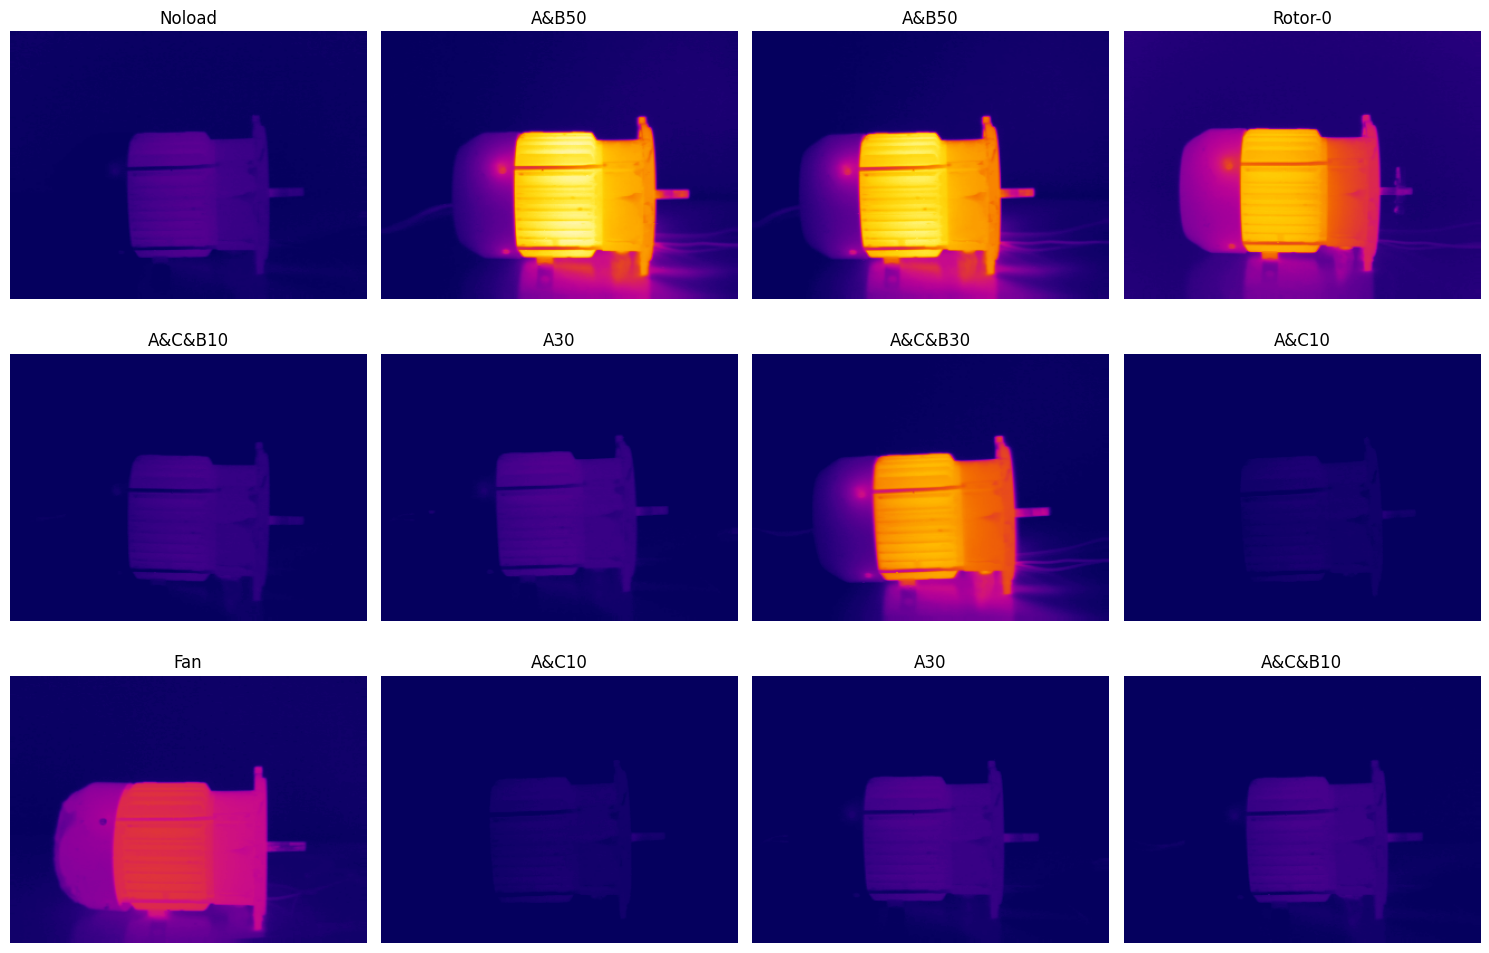

In [58]:
sample_df = df.sample(
    min(12, len(df)),
    random_state=42
)

plt.figure(figsize=(15, 10))

for i, (_, row) in enumerate(sample_df.iterrows()):
    img = Image.open(row["filepath"])

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.title(row["class"])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [59]:
print("Total images:", len(df))
print("Total classes:", df["class"].nunique())

print("\nImages per class:")
print(df["class"].value_counts().sort_index())

Total images: 369
Total classes: 11

Images per class:
class
A&B50      38
A&C&B10    31
A&C&B30    42
A&C10      31
A&C30      38
A10        34
A30        37
A50        35
Fan        28
Noload     25
Rotor-0    30
Name: count, dtype: int64


In [60]:
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["class"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["class"],
    random_state=42
)

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTotal:", len(train_df) + len(val_df) + len(test_df))

Train images: 258
Validation images: 55
Test images: 56

Total: 369


In [61]:
print("TRAIN:")
print(train_df["class"].value_counts().sort_index())

print("\nVALIDATION:")
print(val_df["class"].value_counts().sort_index())

print("\nTEST:")
print(test_df["class"].value_counts().sort_index())

TRAIN:
class
A&B50      27
A&C&B10    22
A&C&B30    29
A&C10      22
A&C30      26
A10        24
A30        26
A50        24
Fan        20
Noload     17
Rotor-0    21
Name: count, dtype: int64

VALIDATION:
class
A&B50      5
A&C&B10    5
A&C&B30    6
A&C10      5
A&C30      6
A10        5
A30        5
A50        5
Fan        4
Noload     4
Rotor-0    5
Name: count, dtype: int64

TEST:
class
A&B50      6
A&C&B10    4
A&C&B30    7
A&C10      4
A&C30      6
A10        5
A30        6
A50        6
Fan        4
Noload     4
Rotor-0    4
Name: count, dtype: int64


In [62]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

# Create class → integer mapping
class_names = sorted(df["class"].unique())

class_to_index = {
    class_name: index
    for index, class_name in enumerate(class_names)
}

print("Class mapping:")
for name, index in class_to_index.items():
    print(f"{index}: {name}")

Class mapping:
0: A&B50
1: A&C&B10
2: A&C&B30
3: A&C10
4: A&C30
5: A10
6: A30
7: A50
8: Fan
9: Noload
10: Rotor-0


In [8]:
def load_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.image.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = tf.cast(image, tf.float32)

    return image, label

In [64]:
def create_dataset(dataframe, shuffle=False):
    filepaths = dataframe["filepath"].values

    labels = np.array([
        class_to_index[c]
        for c in dataframe["class"]
    ], dtype=np.int32)

    dataset = tf.data.Dataset.from_tensor_slices(
        (filepaths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


train_ds = create_dataset(train_df, shuffle=True)
val_ds = create_dataset(val_df, shuffle=False)
test_ds = create_dataset(test_df, shuffle=False)

print("TensorFlow datasets created successfully.")

TensorFlow datasets created successfully.


In [65]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print("Image data type:", images.dtype)
print("Minimum pixel value:", tf.reduce_min(images).numpy())
print("Maximum pixel value:", tf.reduce_max(images).numpy())

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 255.0


In [68]:
NUM_CLASSES = len(class_names)

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = models.Model(
    inputs=inputs,
    outputs=outputs
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ efficientnetb0 (Functional)          │ (None, 7, 7, 1280)          │       4,049,571 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 11)                  │          14,091 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 4,063,662 (15.50 MB)

 Trainable params: 14,091 (55.04 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [69]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [70]:
sample_images, sample_labels = next(iter(train_ds))

predictions = model(sample_images)

print("Input shape:", sample_images.shape)
print("Output shape:", predictions.shape)
print("First prediction:", predictions[0].numpy())
print("Predicted class:", class_names[np.argmax(predictions[0].numpy())])
print("Actual class:", class_names[sample_labels[0].numpy()])

Input shape: (16, 224, 224, 3)
Output shape: (16, 11)
First prediction: [0.0734488  0.12169473 0.06849844 0.06421502 0.09340223 0.03021681
 0.05837757 0.08825621 0.27403393 0.05182212 0.07603411]
Predicted class: Fan
Actual class: Fan


In [72]:
MODEL_DIR = Path(
    r"C:\Users\saqib\Desktop\SEM 7\mp\source code\models"
)

MODEL_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = MODEL_DIR / "thermal_fault_best_phase1.keras"

callbacks_phase1 = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("Callbacks ready.")

Callbacks ready.


In [73]:
EPOCHS_PHASE1 = 15

history_phase1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_PHASE1,
    callbacks=callbacks_phase1
)

Epoch 1/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 370ms/step - accuracy: 0.1343 - loss: 2.3408
Epoch 1: val_loss improved from None to 1.59251, saving model to C:\Users\saqib\Desktop\SEM 7\mp\source code\models\thermal_fault_best_phase1.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 23s 657ms/step - accuracy: 0.1899 - loss: 2.1431 - val_accuracy: 0.3636 - val_loss: 1.5925 - learning_rate: 0.0010
Epoch 2/15
16/17 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 0.4449 - loss: 1.5693
Epoch 2: val_loss improved from 1.59251 to 1.18674, saving model to C:\Users\saqib\Desktop\SEM 7\mp\source code\models\thermal_fault_best_phase1.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 408ms/step - accuracy: 0.4690 - loss: 1.5070 - val_accuracy: 0.7636 - val_loss: 1.1867 - learning_rate: 0.0010
Epoch 3/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step - accuracy: 0.6443 - loss: 1.2091
Epoch 3: val_loss improved from 1.18674 to 0.98433, saving model to C:\Users\saqib\Desktop\SEM 7\mp\source code\models\thermal_fault_best_phase1.keras
17/17 ━━━

In [74]:
base_model.trainable = True

for layer in base_model.layers[:-30]:
    layer.trainable = False

for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.trainable_weights
])

non_trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.non_trainable_weights
])

print("Trainable parameters:", trainable_params)
print("Non-trainable parameters:", non_trainable_params)

Trainable parameters: 1497451
Non-trainable parameters: 2566211.0


In [75]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model recompiled for fine-tuning.")

Model recompiled for fine-tuning.


In [76]:
checkpoint_path_phase2 = MODEL_DIR / "thermal_fault_best_phase2.keras"

callbacks_phase2 = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),

    ModelCheckpoint(
        filepath=str(checkpoint_path_phase2),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

In [77]:
history_phase2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks_phase2
)

Epoch 1/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 377ms/step - accuracy: 0.8935 - loss: 0.4351
Epoch 1: val_loss improved from None to 0.33740, saving model to C:\Users\saqib\Desktop\SEM 7\mp\source code\models\thermal_fault_best_phase2.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 19s 658ms/step - accuracy: 0.8798 - loss: 0.4431 - val_accuracy: 0.9818 - val_loss: 0.3374 - learning_rate: 1.0000e-05
Epoch 2/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 344ms/step - accuracy: 0.8930 - loss: 0.4099
Epoch 2: val_loss improved from 0.33740 to 0.32594, saving model to C:\Users\saqib\Desktop\SEM 7\mp\source code\models\thermal_fault_best_phase2.keras
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 445ms/step - accuracy: 0.8915 - loss: 0.4210 - val_accuracy: 0.9455 - val_loss: 0.3259 - learning_rate: 1.0000e-05
Epoch 3/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.8887 - loss: 0.4311
Epoch 3: val_loss improved from 0.32594 to 0.31585, saving model to C:\Users\saqib\Desktop\SEM 7\mp\source code\models\thermal_fault_best_phase2.keras
1

In [79]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 264ms/step - accuracy: 0.9643 - loss: 0.2920
Test Loss: 0.2920
Test Accuracy: 0.9643
Test Accuracy: 96.43%


In [81]:
y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

              precision    recall  f1-score   support

       A&B50     1.0000    1.0000    1.0000         6
     A&C&B10     1.0000    1.0000    1.0000         4
     A&C&B30     1.0000    1.0000    1.0000         7
       A&C10     1.0000    0.5000    0.6667         4
       A&C30     1.0000    1.0000    1.0000         6
         A10     0.7143    1.0000    0.8333         5
         A30     1.0000    1.0000    1.0000         6
         A50     1.0000    1.0000    1.0000         6
         Fan     1.0000    1.0000    1.0000         4
      Noload     1.0000    1.0000    1.0000         4
     Rotor-0     1.0000    1.0000    1.0000         4

    accuracy                         0.9643        56
   macro avg     0.9740    0.9545    0.9545        56
weighted avg     0.9745    0.9643    0.9613        56



<Figure size 1000x800 with 0 Axes>

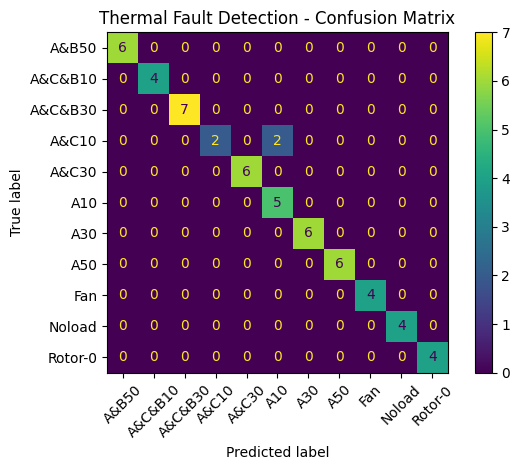

In [83]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    xticks_rotation=45,
    values_format="d"
)

plt.title("Thermal Fault Detection - Confusion Matrix")
plt.tight_layout()
plt.show()

In [84]:
FINAL_MODEL_PATH = MODEL_DIR / "thermal_fault_model.keras"

model.save(FINAL_MODEL_PATH)

print("Model saved to:")
print(FINAL_MODEL_PATH)

Model saved to:
C:\Users\saqib\Desktop\SEM 7\mp\source code\models\thermal_fault_model.keras


In [85]:
CLASS_NAMES_PATH = MODEL_DIR / "class_names.json"

with open(CLASS_NAMES_PATH, "w") as f:
    json.dump(class_names, f, indent=4)

print("Class names saved to:")
print(CLASS_NAMES_PATH)

Class names saved to:
C:\Users\saqib\Desktop\SEM 7\mp\source code\models\class_names.json


In [86]:
loaded_model = tf.keras.models.load_model(
    FINAL_MODEL_PATH
)

test_loss, test_accuracy = loaded_model.evaluate(
    test_ds,
    verbose=0
)

print(f"Loaded model test accuracy: {test_accuracy * 100:.2f}%")

Loaded model test accuracy: 96.43%


In [87]:
for layer in reversed(model.layers):
    try:
        if len(layer.output.shape) == 4:
            print("Candidate layer:", layer.name)
    except:
        pass

Candidate layer: efficientnetb0
Candidate layer: input_layer_1


In [88]:
base_model = model.get_layer("efficientnetb0")

print("Number of layers:", len(base_model.layers))

print("\nLast 20 layers:")
for layer in base_model.layers[-20:]:
    print(
        layer.name,
        "| type:", type(layer).__name__,
        "| output:", layer.output.shape
    )

Number of layers: 238

Last 20 layers:
block6d_project_conv | type: Conv2D | output: (None, 7, 7, 192)
block6d_project_bn | type: BatchNormalization | output: (None, 7, 7, 192)
block6d_drop | type: Dropout | output: (None, 7, 7, 192)
block6d_add | type: Add | output: (None, 7, 7, 192)
block7a_expand_conv | type: Conv2D | output: (None, 7, 7, 1152)
block7a_expand_bn | type: BatchNormalization | output: (None, 7, 7, 1152)
block7a_expand_activation | type: Activation | output: (None, 7, 7, 1152)
block7a_dwconv | type: DepthwiseConv2D | output: (None, 7, 7, 1152)
block7a_bn | type: BatchNormalization | output: (None, 7, 7, 1152)
block7a_activation | type: Activation | output: (None, 7, 7, 1152)
block7a_se_squeeze | type: GlobalAveragePooling2D | output: (None, 1152)
block7a_se_reshape | type: Reshape | output: (None, 1, 1, 1152)
block7a_se_reduce | type: Conv2D | output: (None, 1, 1, 48)
block7a_se_expand | type: Conv2D | output: (None, 1, 1, 1152)
block7a_se_excite | type: Multiply | outp

In [91]:
def make_gradcam_heatmap(
    image,
    model,
    last_conv_layer_name="top_conv",
    pred_index=None
):
    """
    Grad-CAM for the nested EfficientNetB0 model.
    Compatible with the current Keras/TensorFlow setup.
    """

    base_model = model.get_layer("efficientnetb0")

    last_conv_layer = base_model.get_layer(
        last_conv_layer_name
    )

    grad_model = tf.keras.Model(
        inputs=base_model.input,
        outputs=[
            last_conv_layer.output,
            base_model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, base_output = grad_model(
            image,
            training=False
        )

        x = model.layers[-3](base_output)
        x = model.layers[-2](x)
        predictions = model.layers[-1](x)

        if pred_index is None:
            pred_index = tf.argmax(
                predictions[0]
            )

        class_channel = predictions[:, pred_index]

    grads = tape.gradient(
        class_channel,
        conv_outputs
    )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return heatmap.numpy(), int(pred_index)

In [92]:
sample_images, sample_labels = next(iter(test_ds))

sample_image = sample_images[0:1]
actual_label = sample_labels[0].numpy()

heatmap, predicted_index = make_gradcam_heatmap(
    sample_image,
    model,
    last_conv_layer_name="top_conv"
)

print("Actual class:")
print(class_names[actual_label])

print("\nPredicted class:")
print(class_names[predicted_index])

print("\nHeatmap shape:")
print(heatmap.shape)

Actual class:
A&C&B30

Predicted class:
A&C&B30

Heatmap shape:
(7, 7)


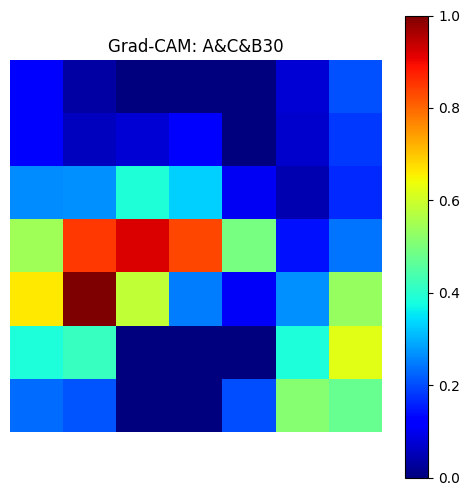

In [93]:
plt.figure(figsize=(6, 6))

plt.imshow(heatmap, cmap="jet")
plt.colorbar()
plt.title(
    f"Grad-CAM: {class_names[predicted_index]}"
)
plt.axis("off")

plt.show()

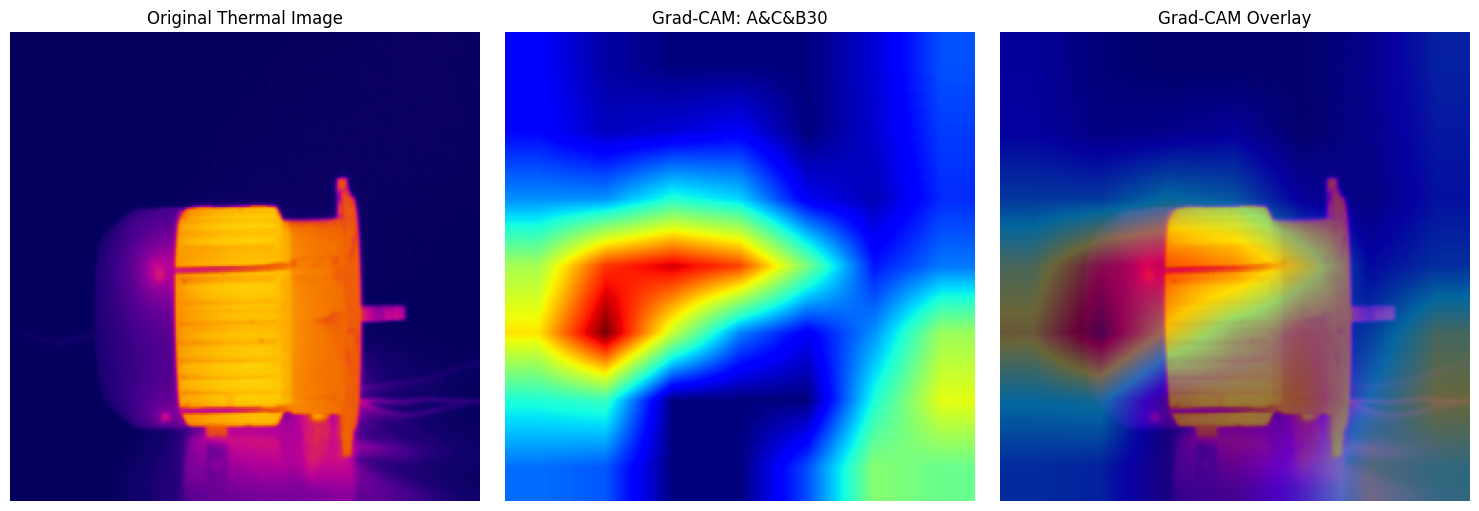

In [95]:
img = sample_image[0].numpy().astype(np.uint8)

img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

heatmap_resized = cv2.resize(
    heatmap,
    (img.shape[1], img.shape[0])
)

heatmap_uint8 = np.uint8(255 * heatmap_resized)

heatmap_color = cv2.applyColorMap(
    heatmap_uint8,
    cv2.COLORMAP_JET
)

overlay = cv2.addWeighted(
    img_bgr,
    0.6,
    heatmap_color,
    0.4,
    0
)

overlay = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original Thermal Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title(f"Grad-CAM: {class_names[predicted_index]}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
PROJECT_DIR = Path(r"C:\Users\saqib\Desktop\SEM 7\mp\source code")

DATA_DIR = PROJECT_DIR / "data" / "raw"
MODEL_DIR = PROJECT_DIR / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

In [5]:
COMPONENT_MAP = {
    "Noload": "Normal",

    "Fan": "Fan",

    "Rotor-0": "Rotor",

    "A10": "Winding",
    "A30": "Winding",
    "A50": "Winding",

    "A&C10": "Winding",
    "A&C30": "Winding",

    "A&B50": "Winding",

    "A&C&B10": "Winding",
    "A&C&B30": "Winding",
}


WINDING_CLASSES = [
    "A10",
    "A30",
    "A50",
    "A&C10",
    "A&C30",
    "A&B50",
    "A&C&B10",
    "A&C&B30",
]


print("Component mapping:")
for k, v in COMPONENT_MAP.items():
    print(f"{k:12} -> {v}")

print("\nWinding classes:")
for cls in WINDING_CLASSES:
    print(cls)

Component mapping:
Noload       -> Normal
Fan          -> Fan
Rotor-0      -> Rotor
A10          -> Winding
A30          -> Winding
A50          -> Winding
A&C10        -> Winding
A&C30        -> Winding
A&B50        -> Winding
A&C&B10      -> Winding
A&C&B30      -> Winding

Winding classes:
A10
A30
A50
A&C10
A&C30
A&B50
A&C&B10
A&C&B30


In [6]:
all_paths = []
all_labels = []

for original_class, component_class in COMPONENT_MAP.items():

    class_dir = DATA_DIR / original_class

    if not class_dir.exists():
        print("WARNING - missing:", class_dir)
        continue

    for image_path in class_dir.iterdir():

        if image_path.suffix.lower() in [
            ".jpg",
            ".jpeg",
            ".png",
            ".bmp"
        ]:

            all_paths.append(str(image_path))
            all_labels.append(component_class)


component_classes = sorted(
    list(set(all_labels))
)

component_to_index = {
    cls: i
    for i, cls in enumerate(component_classes)
}

component_labels = [
    component_to_index[x]
    for x in all_labels
]


print("Component classes:")
for i, cls in enumerate(component_classes):
    print(i, cls)

print("\nTotal images:", len(all_paths))

Component classes:
0 Fan
1 Normal
2 Rotor
3 Winding

Total images: 369


In [7]:
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    all_paths,
    component_labels,
    test_size=0.30,
    stratify=component_labels,
    random_state=SEED
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    stratify=temp_labels,
    random_state=SEED
)


print("Stage 1 dataset:")
print("Train:", len(train_paths))
print("Validation:", len(val_paths))
print("Test:", len(test_paths))

Stage 1 dataset:
Train: 258
Validation: 55
Test: 56


In [9]:
def make_dataset(paths, labels, shuffle=False):

    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        ds = ds.shuffle(
            len(paths),
            seed=SEED
        )

    ds = ds.batch(BATCH_SIZE)

    ds = ds.prefetch(
        tf.data.AUTOTUNE
    )

    return ds

In [10]:
component_train_ds = make_dataset(
    train_paths,
    train_labels,
    shuffle=True
)

component_val_ds = make_dataset(
    val_paths,
    val_labels
)

component_test_ds = make_dataset(
    test_paths,
    test_labels
)


print(
    next(iter(component_train_ds))[0].shape
)

(16, 224, 224, 3)


In [11]:
component_base = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(224, 224, 3)
)

component_base.trainable = False


component_model = tf.keras.Sequential([ component_base, tf.keras.layers.GlobalAveragePooling2D(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(len(component_classes), activation="softmax")])


component_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])


component_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [12]:
component_checkpoint = (MODEL_DIR/"component_classifier.keras")


callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
    tf.keras.callbacks.ModelCheckpoint(component_checkpoint, monitor="val_loss", save_best_only=True)
]


history_component = component_model.fit(component_train_ds, validation_data=component_val_ds, epochs=15, callbacks=callbacks)

Epoch 1/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 20s 646ms/step - accuracy: 0.7326 - loss: 0.7409 - val_accuracy: 0.7818 - val_loss: 0.5363 - learning_rate: 0.0010
Epoch 2/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 500ms/step - accuracy: 0.8178 - loss: 0.5038 - val_accuracy: 0.8545 - val_loss: 0.3822 - learning_rate: 0.0010
Epoch 3/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 423ms/step - accuracy: 0.8953 - loss: 0.3598 - val_accuracy: 0.8909 - val_loss: 0.3059 - learning_rate: 0.0010
Epoch 4/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 436ms/step - accuracy: 0.8876 - loss: 0.3097 - val_accuracy: 0.9273 - val_loss: 0.2652 - learning_rate: 0.0010
Epoch 5/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 463ms/step - accuracy: 0.9147 - loss: 0.2708 - val_accuracy: 0.9273 - val_loss: 0.2333 - learning_rate: 0.0010
Epoch 6/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 485ms/step - accuracy: 0.9380 - loss: 0.2209 - val_accuracy: 0.9273 - val_loss: 0.2088 - learning_rate: 0.0010
Epoch 7/15
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 448ms/step - accuracy: 0.9341 - loss: 0.2164 -

In [13]:
component_base.trainable = True

for layer in component_base.layers[:-30]:
    layer.trainable = False

for layer in component_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

component_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history_component_ft = component_model.fit( component_train_ds, validation_data=component_val_ds, epochs=10, callbacks=callbacks)

Epoch 1/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 26s 778ms/step - accuracy: 0.9419 - loss: 0.1324 - val_accuracy: 0.9636 - val_loss: 0.1273 - learning_rate: 1.0000e-05
Epoch 2/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 524ms/step - accuracy: 0.9612 - loss: 0.1324 - val_accuracy: 0.9636 - val_loss: 0.1225 - learning_rate: 1.0000e-05
Epoch 3/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 9s 532ms/step - accuracy: 0.9690 - loss: 0.1105 - val_accuracy: 0.9636 - val_loss: 0.1175 - learning_rate: 1.0000e-05
Epoch 4/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 10s 569ms/step - accuracy: 0.9612 - loss: 0.1191 - val_accuracy: 0.9636 - val_loss: 0.1111 - learning_rate: 1.0000e-05
Epoch 5/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 485ms/step - accuracy: 0.9612 - loss: 0.1098 - val_accuracy: 0.9636 - val_loss: 0.1079 - learning_rate: 1.0000e-05
Epoch 6/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 8s 486ms/step - accuracy: 0.9496 - loss: 0.1263 - val_accuracy: 0.9636 - val_loss: 0.1039 - learning_rate: 1.0000e-05
Epoch 7/10
17/17 ━━━━━━━━━━━━━━━━━━━━ 7s 425ms/step - accuracy

In [15]:
component_model = tf.keras.models.load_model(component_checkpoint)

loss, accuracy = component_model.evaluate(component_test_ds)

print(f"Component classifier accuracy: {accuracy * 100:.2f}%")

4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 285ms/step - accuracy: 0.9464 - loss: 0.1030
Component classifier accuracy: 94.64%


In [16]:
with open(MODEL_DIR / "component_class_names.json", "w") as f:
    json.dump(component_classes, f, indent=4)

print("Saved component class names.")

Saved component class names.


In [17]:
winding_paths = []
winding_labels = []


for class_name in WINDING_CLASSES:
    class_dir = DATA_DIR / class_name

    for image_path in class_dir.iterdir():
        if image_path.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:
            winding_paths.append(str(image_path))
            winding_labels.append(class_name)

winding_classes = sorted(list(set(winding_labels)))

winding_to_index = {cls: i for i, cls in enumerate(winding_classes)}

winding_numeric_labels = [winding_to_index[x] for x in winding_labels]

print("Winding classes:")

for i, cls in enumerate(winding_classes):
    print(i, cls)

print("Total winding images:", len(winding_paths))

Winding classes:
0 A&B50
1 A&C&B10
2 A&C&B30
3 A&C10
4 A&C30
5 A10
6 A30
7 A50
Total winding images: 286


In [18]:
w_train_paths, w_temp_paths, w_train_labels, w_temp_labels = train_test_split(winding_paths, winding_numeric_labels, test_size=0.30, stratify=winding_numeric_labels, random_state=SEED)

w_val_paths, w_test_paths, w_val_labels, w_test_labels = train_test_split(w_temp_paths, w_temp_labels, test_size=0.50, stratify=w_temp_labels, random_state=SEED)

print("Winding dataset:")

print("Train:", len(w_train_paths))

print("Validation:", len(w_val_paths))

print("Test:", len(w_test_paths))

Winding dataset:
Train: 200
Validation: 43
Test: 43


In [19]:
winding_train_ds = make_dataset(w_train_paths, w_train_labels, shuffle=True)

winding_val_ds = make_dataset(w_val_paths, w_val_labels)

winding_test_ds = make_dataset(w_test_paths, w_test_labels)

In [20]:
winding_base = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(224, 224, 3))

winding_base.trainable = False

winding_model = tf.keras.Sequential([winding_base, tf.keras.layers.GlobalAveragePooling2D(), tf.keras.layers.Dropout(0.3), tf.keras.layers.Dense(len(winding_classes),activation="softmax")])

winding_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

winding_checkpoint = (MODEL_DIR /"winding_fault_classifier.keras")

winding_callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-6),
    tf.keras.callbacks.ModelCheckpoint(winding_checkpoint, monitor="val_loss", save_best_only=True)
]

In [21]:
history_winding = winding_model.fit(winding_train_ds, validation_data=winding_val_ds, epochs=15, callbacks=winding_callbacks)

Epoch 1/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 708ms/step - accuracy: 0.3650 - loss: 1.8025 - val_accuracy: 0.6279 - val_loss: 1.3564 - learning_rate: 0.0010
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 455ms/step - accuracy: 0.4800 - loss: 1.3171 - val_accuracy: 0.8837 - val_loss: 1.0260 - learning_rate: 0.0010
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 488ms/step - accuracy: 0.6450 - loss: 1.0497 - val_accuracy: 0.9767 - val_loss: 0.8412 - learning_rate: 0.0010
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 521ms/step - accuracy: 0.7300 - loss: 0.8730 - val_accuracy: 0.8372 - val_loss: 0.7264 - learning_rate: 0.0010
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 446ms/step - accuracy: 0.7400 - loss: 0.8180 - val_accuracy: 0.9535 - val_loss: 0.6339 - learning_rate: 0.0010
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 495ms/step - accuracy: 0.7700 - loss: 0.7339 - val_accuracy: 0.9070 - val_loss: 0.5674 - learning_rate: 0.0010
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 455ms/step - accuracy: 0.8250 - loss: 0.6588 -

In [22]:
winding_base.trainable = True

for layer in winding_base.layers[:-30]:
    layer.trainable = False


for layer in winding_base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

winding_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history_winding_ft = winding_model.fit(winding_train_ds, validation_data=winding_val_ds, epochs=10, callbacks=winding_callbacks)

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 17s 746ms/step - accuracy: 0.8800 - loss: 0.4065 - val_accuracy: 0.9767 - val_loss: 0.3050 - learning_rate: 1.0000e-05
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 499ms/step - accuracy: 0.9000 - loss: 0.3891 - val_accuracy: 0.9767 - val_loss: 0.2916 - learning_rate: 1.0000e-05
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 497ms/step - accuracy: 0.8750 - loss: 0.3930 - val_accuracy: 0.9535 - val_loss: 0.2810 - learning_rate: 1.0000e-05
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step - accuracy: 0.9050 - loss: 0.3824 - val_accuracy: 1.0000 - val_loss: 0.2718 - learning_rate: 1.0000e-05
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 504ms/step - accuracy: 0.9250 - loss: 0.3384 - val_accuracy: 1.0000 - val_loss: 0.2644 - learning_rate: 1.0000e-05
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 543ms/step - accuracy: 0.9150 - loss: 0.3410 - val_accuracy: 1.0000 - val_loss: 0.2549 - learning_rate: 1.0000e-05
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 521ms/step - accuracy:

In [23]:
winding_model = tf.keras.models.load_model(winding_checkpoint)

loss, accuracy = winding_model.evaluate(winding_test_ds)

print(f"Winding classifier accuracy: {accuracy * 100:.2f}%")

3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 249ms/step - accuracy: 0.9070 - loss: 0.2691
Winding classifier accuracy: 90.70%


In [24]:
with open(MODEL_DIR / "winding_class_names.json", "w") as f:
    json.dump(winding_classes, f, indent=4)

print("Saved winding class names.")

Saved winding class names.
